### 4.4 Definição do Hardware

In [1]:
# Verificar o status da GPU
!nvidia-smi

Mon Jul  6 23:17:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 4.5 Configuração do Ambiente (YOLOv5 e Dependências)

In [2]:
# Garantir que estamos no diretório base e que não existe um yolov5 anterior
%cd /content
!rm -rf yolov5  # Remove qualquer clone anterior

# Clonar o repositório YOLOv5
!git clone https://github.com/ultralytics/yolov5
%cd yolov5

# Instalar dependências do YOLOv5
%pip install -qr requirements.txt
%pip install -q roboflow

/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18420, done.
remote: Counting objects: 100% (85/85), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 18420 (delta 58), reused 28 (delta 28), pack-reused 18335 (from 3)
Receiving objects: 100% (18420/18420), 17.53 MiB | 25.86 MiB/s, done.
Resolving deltas: 100% (12512/12512), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 46.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.1/131.1 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 260.3/260.3 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 17.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 84.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 143.2 MB/s eta 0:00:0000:01


### Conexão com a Nuvem (Google Drive)

In [3]:
from google.colab import drive
import os

# Montar o Google Drive
drive.mount('/content/drive')

# Desmontar o Google Drive
# drive.flush_and_unmount()

Mounted at /content/drive


### 4.3 Pré-processamento dos Datasets (Pipeline MLOps Automático)

In [4]:
import shutil
import yaml
import os

# 1. Caminhos
caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Yolo_dataset.zip"
pasta_local_vm = "/content/Yolo_dataset"
yaml_path = f"{pasta_local_vm}/data.yaml"

# 2. Criar a pasta para não espalhar os arquivos
os.makedirs(pasta_local_vm, exist_ok=True)

# 3. Automação MLOps (Verifica se a pasta de imagens existe)
if not os.path.exists(f"{pasta_local_vm}/images"):
    print("🚚 1. Copiando o ZIP do Drive para o SSD da VM...")
    shutil.copy2(caminho_zip_drive, "/content/Yolo_dataset.zip")
    
    print("📦 2. Descompactando na velocidade da luz...")
    shutil.unpack_archive("/content/Yolo_dataset.zip", pasta_local_vm)
    print(" ✅ Descompactação concluída.")
else:
    print("✅ O dataset já está descompactado no SSD desta sessão!")

# 4. A Cirurgia do YAML (Só atua se o caminho estiver errado!)
if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)
    
    # Ele confere: O caminho atual já é o da VM local?
    if data.get('path') != pasta_local_vm:
        print("🔧 3. Ajustando o caminho no data.yaml existente...")
        data['path'] = pasta_local_vm
        with open(yaml_path, 'w') as f:
            yaml.dump(data, f, sort_keys=False)
        print(" 🚀 data.yaml atualizado com sucesso!")
else:
    print(" ⚠️ data.yaml não encontrado! O YOLO vai precisar dele para rodar.")

# 5. Aponta a variável global do YOLO para o SSD local
os.environ["DATASET_DIRECTORY"] = pasta_local_vm

🚚 1. Copiando o ZIP do Drive para o SSD da VM...
📦 2. Descompactando na velocidade da luz...
 ✅ Descompactação concluída.
🔧 3. Ajustando o caminho no data.yaml existente...
 🚀 data.yaml atualizado com sucesso!


### 4.6 Definição de Hiperparâmetros e 4.7 Treinamento do Modelo

In [5]:
import os
import torch
from datetime import datetime

# 1. Verificar se o PyTorch reconhece a GPU (Vital para garantir que o Colab te deu a placa de vídeo de volta)
print(f"Setup completo. Usando torch {torch.__version__} ({torch.cuda.get_device_properties(0).name if torch.cuda.is_available() else 'ATENÇÃO: MODO CPU!'})")

# 2. Destrói arquivos de cache corrompidos (Garante que o YOLO leia o dataset do zero ao retomar)
!rm -f "$DATASET_DIRECTORY/labels/train/*.cache"
!rm -f "$DATASET_DIRECTORY/labels/val/*.cache"
!rm -f "$DATASET_DIRECTORY/images/train/*.cache"
!rm -f "$DATASET_DIRECTORY/images/val/*.cache"

# 3. Desativa o Weights & Biases
os.environ["WANDB_DISABLED"] = "true"
os.environ["WANDB_MODE"] = "disabled"
print("W&B desativado para este notebook.")

# 4. Variável de projeto — diretório base no Drive
DIRETORIO_DRIVE_V5 = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5"
os.environ["DIRETORIO_DRIVE_V5"] = DIRETORIO_DRIVE_V5

# 5. Gera uma string com a data e hora exata do início do treino (Model Registry)
agora = datetime.now()
nome_treino = agora.strftime("Treino_%Y-%m-%d_%Hh%M")
os.environ["NOME_TREINO"] = nome_treino
print(f"🚀 Iniciando YOLOv5. Salvando direto no Drive em: {DIRETORIO_DRIVE_V5}/{nome_treino}")

# 6. Executa o treinamento salvando diretamente no Drive 
!python train.py --batch 32 --epochs 2 --data "$DATASET_DIRECTORY/data.yaml" --weights yolov5s.pt --workers 4 --cache disk --project "$DIRETORIO_DRIVE_V5" --name "$NOME_TREINO"

Setup completo. Usando torch 2.11.0+cu128 (Tesla T4)
W&B desativado para este notebook.
🚀 Iniciando YOLOv5. Salvando direto no Drive em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Treino_2026-07-06_23h19
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
wandb: WARNING ⚠️ wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
train: weights=yolov5s.pt, cfg=, data=/content/Yolo_dataset/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=2, batch_size=32, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, 

### 4.7 Inferência com o Conjunto de Testes

In [6]:
import os

# 1. Recupera as variáveis de ambiente definidas na célula de treino
DIRETORIO_DRIVE_V5 = os.environ.get("DIRETORIO_DRIVE_V5", "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5")
nome_treino = os.environ.get("NOME_TREINO", "exp")

# 2. Constrói os caminhos diretamente do Drive 
CAMINHO_MODELO = f"{DIRETORIO_DRIVE_V5}/{nome_treino}/weights/best.pt"
nome_teste = nome_treino.replace("Treino", "Teste")

print("🔍 Testando o modelo contra dados nunca vistos (Conjunto de Teste)...")
print(f"Caminho do Modelo: {CAMINHO_MODELO}")

# 3. Transforma as variáveis do Python em Variáveis de Ambiente do Linux
os.environ["CAMINHO_MODELO"] = CAMINHO_MODELO
os.environ["NOME_TESTE"] = nome_teste

# 4. Executa o teste salvando diretamente no Drive 
!python val.py --weights "$CAMINHO_MODELO" --data "$DATASET_DIRECTORY/data.yaml" --task test --project "$DIRETORIO_DRIVE_V5" --name "$NOME_TESTE"

🔍 Testando o modelo contra dados nunca vistos (Conjunto de Teste)...
Caminho do Modelo: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Treino_2026-07-06_23h19/weights/best.pt
val: data=/content/Yolo_dataset/data.yaml, weights=['/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Treino_2026-07-06_23h19/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=test, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5, name=Teste_2026-07-06_23h19, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-509-gfd0f6da7 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 157 layers, 7023610 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /content/Yolo_dataset/labels/test... 1034 images, 0 background

### 4.8 Coleta De metricas visuais

📊 Lendo Métricas Oficiais direto do Google Drive...
------------------------------------------------------------
>>> MÉTRICAS DE TREINAMENTO (Acurácia e Loss)


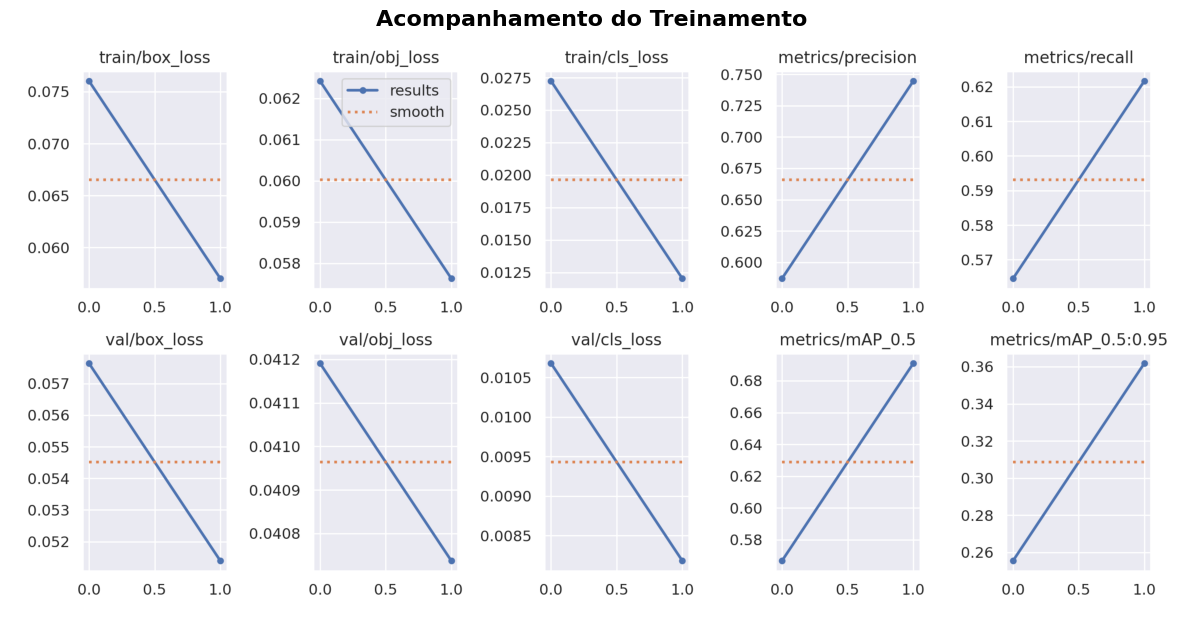


>>> MÉTRICAS DE TESTE (Avaliação Final)


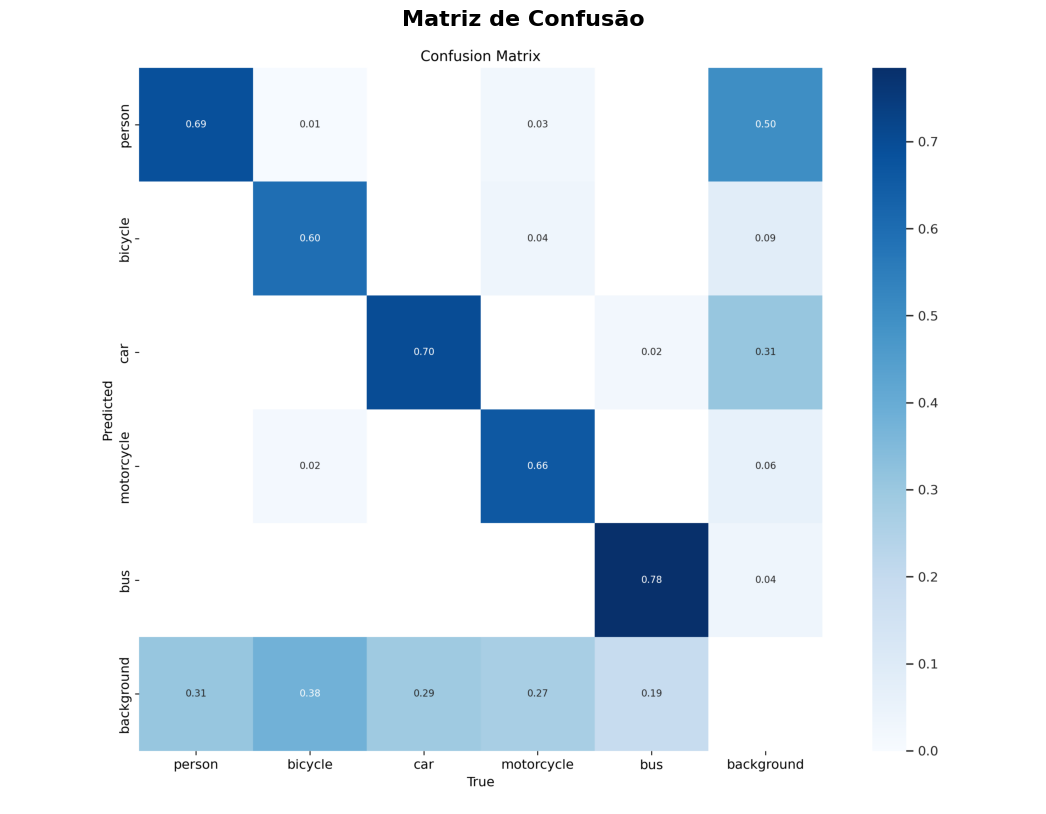

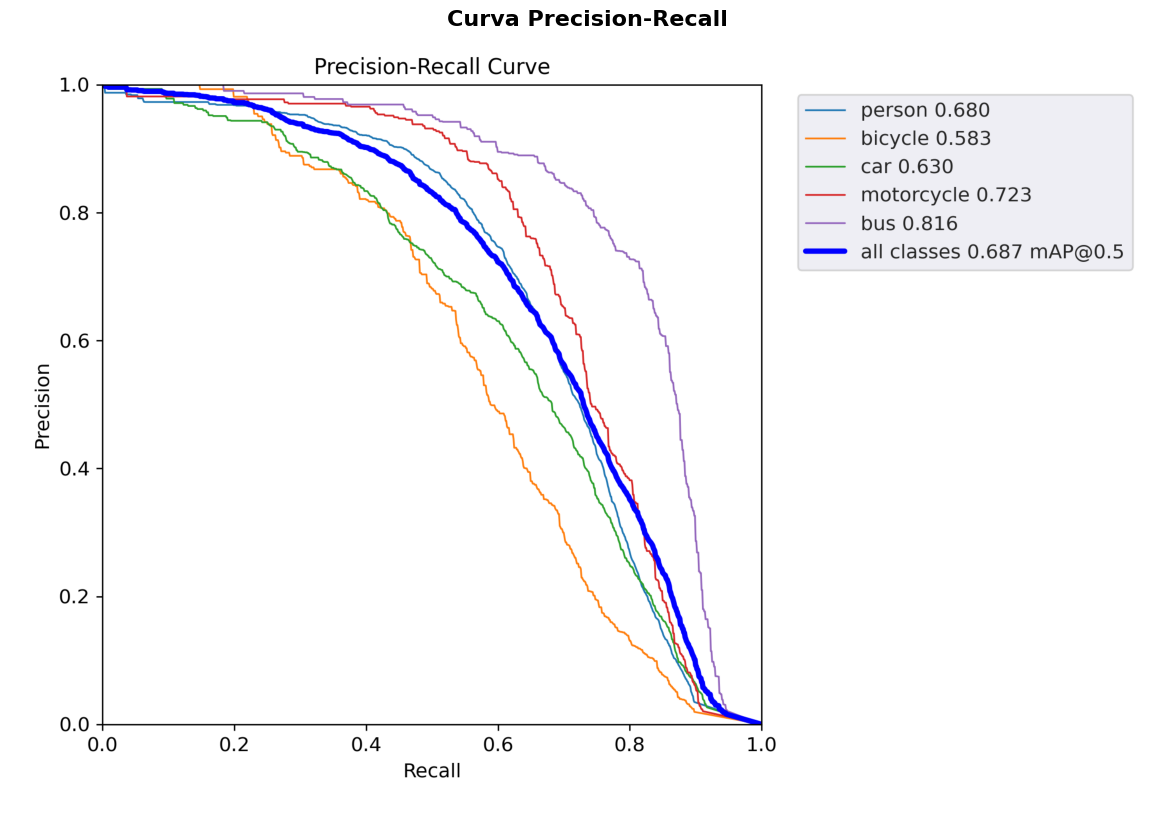


>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)


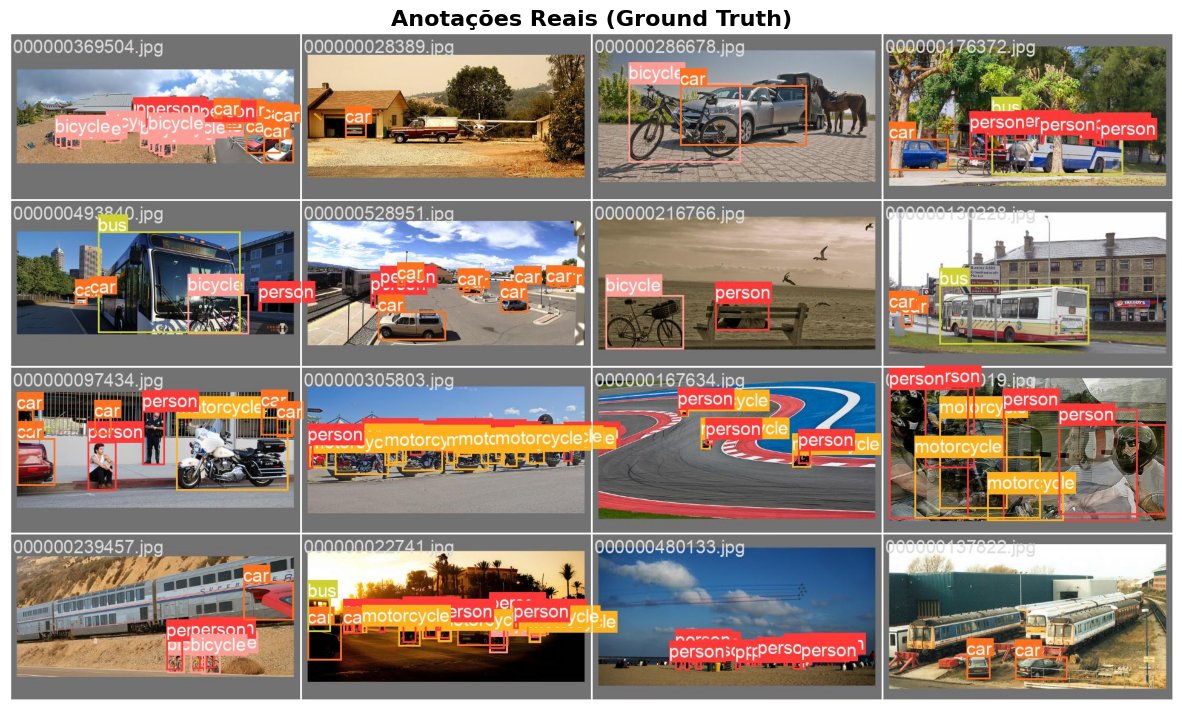

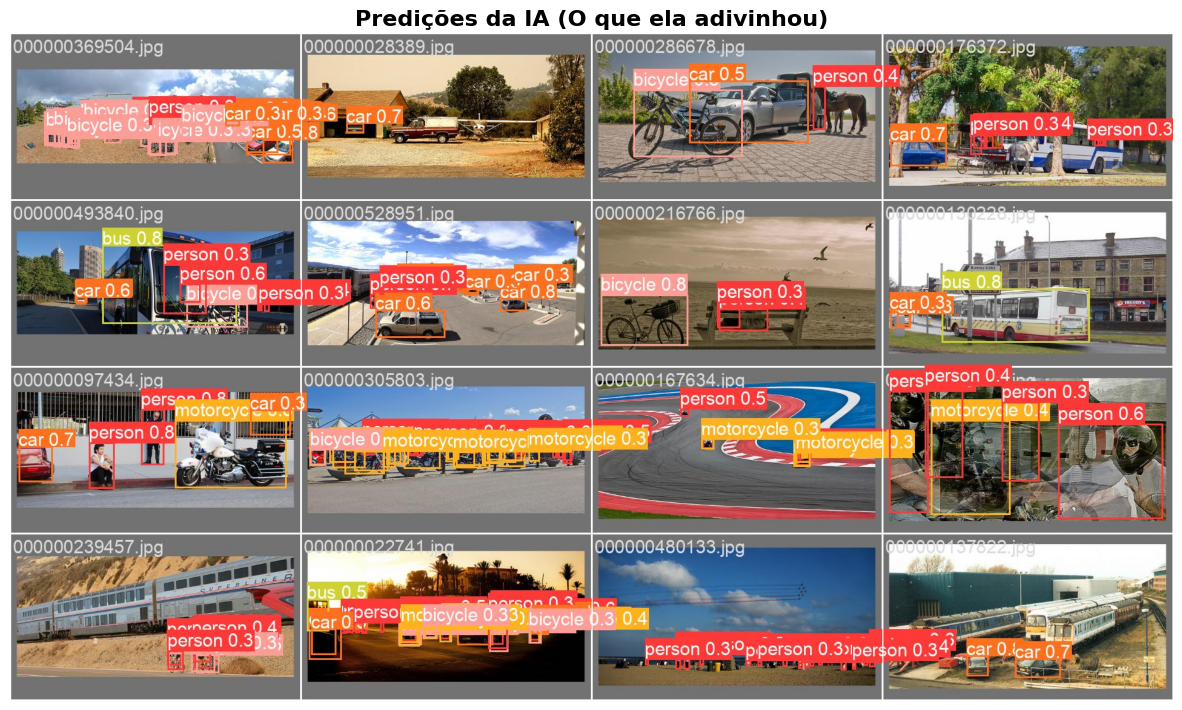


✅ Fluxo finalizado! O seu modelo está treinado, testado e com backup garantido.


In [7]:
import matplotlib.pyplot as plt
import cv2
import os

def mostrar_metrica(caminho_imagem, titulo):
    """Lê uma imagem do disco e a exibe no Colab."""
    img = cv2.imread(caminho_imagem)
    if img is not None:
        plt.figure(figsize=(15, 10))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(titulo, fontsize=16, fontweight='bold')
        plt.axis('off')
        plt.show()
    else:
        print(f"⚠️ Métrica não encontrada no Drive: {caminho_imagem}")

# 1. Recupera os nomes
DIRETORIO_DRIVE_V5 = os.environ.get("DIRETORIO_DRIVE_V5", "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5")
nome_treino = os.environ.get("NOME_TREINO", "exp")
nome_teste = nome_treino.replace("Treino", "Teste")

# 2. AGORA TUDO VEM DO SEU DRIVE! (Segurança Máxima)
pasta_treino_drive = f"{DIRETORIO_DRIVE_V5}/{nome_treino}"
pasta_teste_drive = f"{DIRETORIO_DRIVE_V5}/{nome_teste}"

print(f"📊 Lendo Métricas Oficiais direto do Google Drive...")
print("-" * 60)

# 3. Gráficos do Treinamento
print(">>> MÉTRICAS DE TREINAMENTO (Acurácia e Loss)")
mostrar_metrica(f"{pasta_treino_drive}/results.png", "Acompanhamento do Treinamento")

# 4. Gráficos do Teste
print("\n>>> MÉTRICAS DE TESTE (Avaliação Final)")
mostrar_metrica(f"{pasta_teste_drive}/confusion_matrix.png", "Matriz de Confusão")
mostrar_metrica(f"{pasta_teste_drive}/PR_curve.png", "Curva Precision-Recall")

# 5. Visualização Prática
print("\n>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)")
mostrar_metrica(f"{pasta_teste_drive}/val_batch0_labels.jpg", "Anotações Reais (Ground Truth)")
mostrar_metrica(f"{pasta_teste_drive}/val_batch0_pred.jpg", "Predições da IA (O que ela adivinhou)")

print("\n✅ Fluxo finalizado! O seu modelo está treinado, testado e com backup garantido.")